# Evolution du comportement d'achat

**Objectif**: Comprendre comment le comportement d'achat varie selon le profil du client (occasionnel, typique, fidèle) et identifier les produits qui génèrent de la récurrence.

**Questions à traiter**:

1. Comment évoluent les quantités d'achat selon le segment client ?
2. Quel est le taux de réachat global et par segment ?
3. Quels sont les produits les plus rachetés ?

**Impact business attendu**:
Identifier à quel moment les clients deviennent fidèles pour concentrer les actions de rétention sur les commandes critiques.

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('..')

from src.data_loader import get_data
from src.features import enrich_dataframe

# Style global
sns.set_theme(style="whitegrid", palette="muted", font_scale=1)
plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# Chargement
data = get_data(raw_dir="../data/raw/",processed_path="../data/processed/merged_orders.parquet")
data = enrich_dataframe(data)
print(f"Dataset: {data.shape[0]:,} lignes, {data.shape[1]:,} colonnes")
data.head(3)


Chargement depuis le cache .parquet
Dataset: 32,434,489 lignes, 21 colonnes


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,...,department_id,aisle,department,user_total_orders,customer_segment,cart_size,dept_per_order,aisles_per_order,day_name,hour_period
0,2,33120,1,1,202279,3,5,9,8.0,Organic Egg Whites,...,16,eggs,dairy eggs,8,typique,9,3,8,Vendredi,Matin
1,2,28985,2,1,202279,3,5,9,8.0,Michigan Organic Kale,...,4,fresh vegetables,produce,8,typique,9,3,8,Vendredi,Matin
2,2,9327,3,0,202279,3,5,9,8.0,Garlic Powder,...,13,spices seasonings,pantry,8,typique,9,3,8,Vendredi,Matin


## Vérification rapide de la segmentation

Avant d'analyser =, on vérifie que les 3 segments sont bien répartis et cohérents avec les quartiles observés dans le notebook 01.

### Distribution des utilisateurs par segment

In [3]:
users = data.groupby("user_id").agg(
    segment=("customer_segment", "first"),
    total_orders=("user_total_orders", "first")
).reset_index()

print("Répartition des utilisateurs par segment :")
print(users["segment"].value_counts().sort_index())
print(f"\nTotal : {len(users):,} utilisateurs")

Répartition des utilisateurs par segment :
segment
occasionnel    73591
typique        84808
fidèle         47810
Name: count, dtype: int64

Total : 206,209 utilisateurs


## 1- Comment évoluent les quantités d'achat selon le segment client ?

On cherche à savoir si les clients fidèles commandent plus d'articles par commandes que les occasionnels, et si la taille du panier évolue au fil des commandes.

L'objectif serait de mettre en place des cartes de fidélité afin de récompenser la fidélité de la clientèle, mais inciterait également à acheter plus.

In [4]:
# Statistiques descriptives de la taille du panier par segment
orders_level = data.groupby(["order_id", "customer_segment", "order_number"]).agg(
    cart_size =("product_id", "count")
).reset_index()

orders_level.groupby("customer_segment")["cart_size"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,314243.0,9.7,7.4,1.0,4.0,8.0,13.0,101.0
typique,1000376.0,10.0,7.5,1.0,5.0,8.0,14.0,121.0
fidèle,1900255.0,10.2,7.5,1.0,5.0,8.0,14.0,145.0


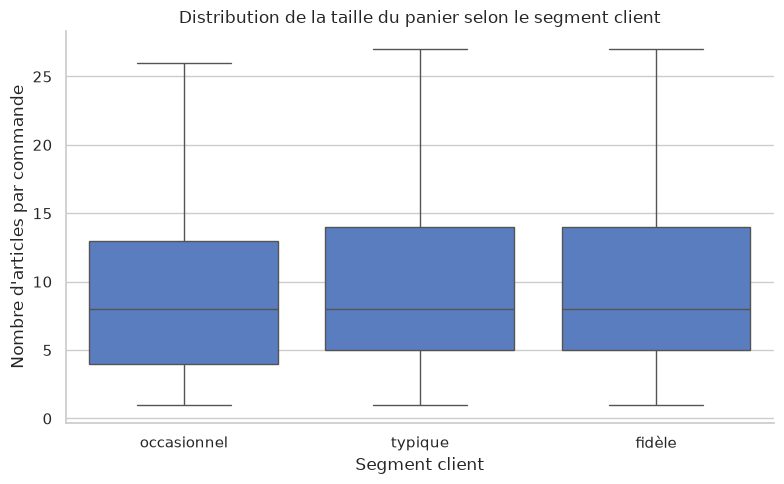

In [6]:
# Visualisation 1: Box plot, distribution de la taille du panier par segment
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=orders_level,
    x="customer_segment",
    y="cart_size",
    showfliers=False,
    ax=ax
)

ax.set_xlabel("Segment client")
ax.set_ylabel("Nombre d'articles par commande")
ax.set_title("Distribution de la taille du panier selon le segment client")

plt.tight_layout()
plt.show()

### Interprétation

D'après les calculs, les trois segments présentent un comportement d'achat homogène en termees de taille de panier.

La **médiane** est identique, 8 articles, quel que soit le segment. L'écart entre occasionnels et fidèles n'est que de **+0.5 article en moyenne**, soit une différence de ~5 %, mais **négligeable en pratique**.

On peut déduire que la fidélité se traduit par une fréquence de commande plus élevée, et non par des paniers plus gros.
Un client fidèle ne remplit pas plus son panier, mais il revient simplement plus souvent.

> **Implication business** : un programme de fidélité classique (carte à points sur le montant) aurait un impact limité puisque la taille du panier est stable. Il serait plus pertinent de **récompenser la fréquence** plutôt que le volume par commande.

Ce graphique en barres rend visible ce que le boxplot masque : les trois barres sont quasi identiques, ce qui renforce visuellement le constat que la fidélité n'augmente pas la taille du panier.